# Task 1 – Data Analysis
**INFO345 – RateBeer dataset**

This notebook loads the RateBeer dataset (Lederrey & West, 2018), explores it, and prepares the filtered data used in `02_models_and_evaluation.ipynb`.

**Before running:** run `00_prepare_data.py` once in the `RateBeer Dataset` folder. It creates `ratings_2012_2017.parquet` and the `stats_full` folder used below.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt

DATA = ".."          # the 'RateBeer Dataset' folder (this notebook lives in its 'project' subfolder)
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 10})
BLUE, ORANGE = "#2a6fb0", "#e07b39"

<details>
<summary><b>💡 What's going on here?</b></summary>

We import the libraries we need:
- **pandas** – works with tables of data (like Excel in Python).
- **numpy** – fast maths on lists of numbers.
- **matplotlib** – draws the figures.

`DATA = ".."` means the data files are in the folder *above* this one (the `RateBeer Dataset` folder). `FIG = "figures"` is where the figures are saved, and `os.makedirs` creates that folder if it doesn't exist yet. The last lines just set a clean, consistent look for all plots and pick two colours.

</details>

In [2]:
# Helper functions used in this notebook
SUBSCORES = ["appearance", "aroma", "palate", "taste", "overall"]
ABV_BINS = [0, 3.5, 4.5, 5.5, 6.5, 7.5, 9, 11, 100]
ABV_LABELS = ["<3.5", "3.5-4.5", "4.5-5.5", "5.5-6.5", "6.5-7.5", "7.5-9", "9-11", "11+"]

def filter_data(ratings, min_user=10, min_item=5, max_iter=20):
    """Repeatedly remove users with < min_user ratings and beers with < min_item ratings
    until every remaining user and beer meets the threshold (k-core filtering)."""
    steps = [("start", len(ratings), ratings.user_id.nunique(), ratings.beer_id.nunique())]
    df = ratings
    for it in range(max_iter):
        n0 = len(df)
        df = df[df.user_id.map(df.user_id.value_counts()) >= min_user]
        df = df[df.beer_id.map(df.beer_id.value_counts()) >= min_item]
        if len(df) == n0:
            break
        steps.append((f"filter round {it + 1}", len(df), df.user_id.nunique(), df.beer_id.nunique()))
    return df.reset_index(drop=True), steps

def item_feature_table(beers, breweries, beer_ids):
    """Content features per beer: style, brewery, brewery country/region, ABV bin."""
    b = beers.set_index("beer_id").loc[beer_ids, ["style", "brewery_id", "abv"]].copy()
    b["country"] = b["brewery_id"].map(breweries.set_index("id")["location"]).fillna("unknown")
    b["abv_bin"] = pd.cut(b["abv"], ABV_BINS, labels=ABV_LABELS, right=False).astype(str)
    b.loc[b["abv"].isna(), "abv_bin"] = "unknown"
    b["style"] = b["style"].fillna("unknown")
    return b.reset_index()

<details>
<summary><b>💡 What's going on here?</b></summary>

This cell defines two helper functions that are used later:

- **`filter_data`** – removes users with fewer than 10 ratings and beers with fewer than 5 ratings. Removing beers can push some users below 10 ratings (and the other way round), so it repeats until nothing changes. This is called *k-core filtering*. It removes the very sparse part of the data, which collaborative filtering can learn almost nothing from.
- **`item_feature_table`** – builds a small table with the *content* of each beer: its style, brewery, the brewery's country/region (from `breweries.csv`) and its alcohol percentage (ABV) grouped into 8 bins such as "4.5–5.5%". These features are what content-based filtering would use.

Nothing is computed yet – the functions are only defined here.

</details>

## 1.1 The full dataset (2000–2017)
The summary tables in `stats_full` were computed over **all** ratings by `00_prepare_data.py`.

In [3]:
per_year = pd.read_csv(f"{DATA}/stats_full/ratings_per_year.csv", index_col=0).n
hist = pd.read_csv(f"{DATA}/stats_full/rating_histogram.csv", index_col=0).n
per_beer = pd.read_csv(f"{DATA}/stats_full/ratings_per_beer.csv", index_col=0).n
per_user = pd.read_csv(f"{DATA}/stats_full/ratings_per_user.csv", index_col=0).n
beers = pd.read_csv(f"{DATA}/beers.csv", low_memory=False)
breweries = pd.read_csv(f"{DATA}/breweries.csv")
users = pd.read_csv(f"{DATA}/users.csv")

overview = pd.Series({
    "Ratings": per_year.sum(),
    "Users who rated": len(per_user),
    "Beers rated": len(per_beer),
    "Beers in beers.csv": len(beers),
    "Breweries": len(breweries),
    "Beer styles": beers["style"].nunique(),
    "Density (%)": 100 * per_year.sum() / (len(per_user) * len(per_beer)),
})
overview.to_frame("value").style.format("{:,.4g}")

,value
Ratings,7.122e+06
Users who rated,7.012e+04
Beers rated,3.967e+05
Beers in beers.csv,4.421e+05
Breweries,2.419e+04
Beer styles,94
Density (%),0.0256


<details>
<summary><b>💡 What's going on here?</b></summary>

We load small summary tables that `00_prepare_data.py` computed over the **full** dataset (all 7.1 million ratings from 2000–2017), plus the beer, brewery and user files.

Then we compute an overview: how many ratings, users, beers, breweries and styles there are, and the **density** – the share of all possible user–beer combinations that actually have a rating. Here the density is only **0.026%**: of all possible user–beer pairs, about 1 in 4,000 has a rating. The rating matrix is almost empty (*sparse*), which is the normal situation for recommender systems and their main challenge.

</details>

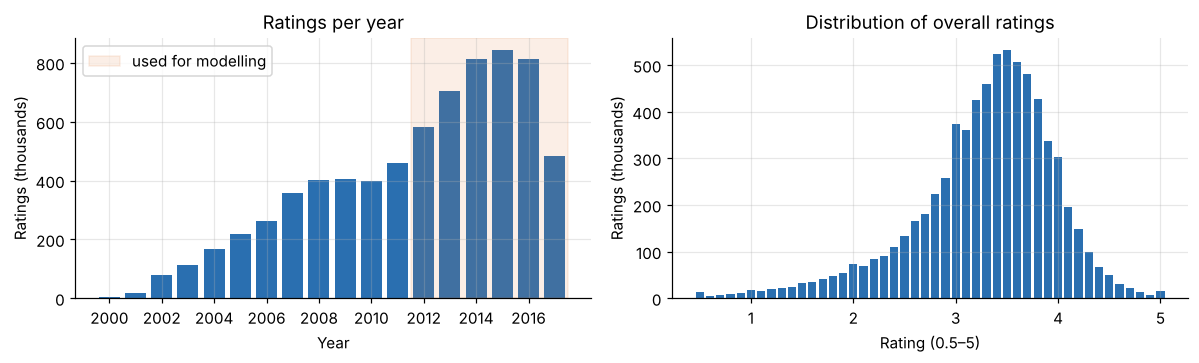

Mean rating 3.29; 2017 only covers part of the year (data collected mid-2017).


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(per_year.index, per_year.values / 1e3, color=BLUE)
ax[0].axvspan(2011.5, 2017.5, color=ORANGE, alpha=.12, label="used for modelling")
ax[0].set(title="Ratings per year", xlabel="Year", ylabel="Ratings (thousands)"); ax[0].legend()
ax[0].set_xticks(range(2000, 2018, 2))
ax[1].bar(hist.index, hist.values / 1e3, width=.08, color=BLUE)
ax[1].set(title="Distribution of overall ratings", xlabel="Rating (0.5–5)", ylabel="Ratings (thousands)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig1_year_and_rating_distribution.png", bbox_inches="tight"); plt.show()
print(f"Mean rating {np.average(hist.index, weights=hist.values):.2f}; "
      f"2017 only covers part of the year (data collected mid-2017).")

<details>
<summary><b>💡 What's going on here?</b></summary>

Two plots:
- **Left – ratings per year:** activity on RateBeer grew steadily up to 2015. The shaded area (2012–2017) is the part we use for modelling. 2017 is lower only because the data was collected in the middle of that year.
- **Right – distribution of ratings:** most ratings lie between 3 and 4, with an average of about 3.3. Very low and very high ratings are rare. This matters for the evaluation: a model that always guesses about 3.3 is already not far off for most ratings.

</details>

### The long tail – the core motivation for the project
Most beers have very few ratings. Collaborative filtering has little or nothing to learn from for these beers.

In [5]:
def share(s, t): return 100 * (s < t).mean()
tail = pd.DataFrame({
    "threshold": ["< 2 ratings", "< 5 ratings", "< 10 ratings", "< 20 ratings"],
    "% of beers": [share(per_beer, t) for t in (2, 5, 10, 20)],
    "% of users": [share(per_user, t) for t in (2, 5, 10, 20)]})
srt = per_beer.sort_values(ascending=False).to_numpy()
top1 = srt[: len(srt) // 100].sum() / srt.sum()
print(f"Top 1% of beers receive {100*top1:.1f}% of all ratings; median ratings per beer = {per_beer.median():.0f}")
tail.style.format({"% of beers": "{:.1f}", "% of users": "{:.1f}"}).hide()

Top 1% of beers receive 34.9% of all ratings; median ratings per beer = 3


threshold,% of beers,% of users
< 2 ratings,27.9,40.1
< 5 ratings,58.1,65.0
< 10 ratings,73.8,75.6
< 20 ratings,84.8,82.8


<details>
<summary><b>💡 What's going on here?</b></summary>

This measures the **long tail**: what share of beers (and users) have fewer than 2, 5, 10 or 20 ratings. For example, **58% of all beers have fewer than 5 ratings**, and 40% of users rated only a single beer.

It also prints how concentrated the ratings are: the 1% most-rated beers receive about 35% of all ratings, while the *median* beer has only 3 ratings. In other words, a few popular beers get most of the attention, and most beers have hardly any ratings – so collaborative filtering has very little to learn from for them.

</details>

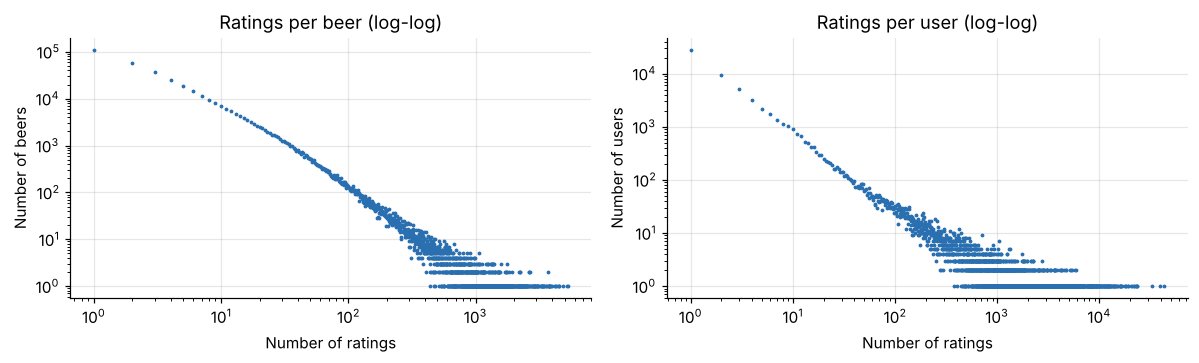

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, s, title in [(ax[0], per_beer, "Ratings per beer"), (ax[1], per_user, "Ratings per user")]:
    vc = s.value_counts().sort_index()
    a.loglog(vc.index, vc.values, ".", ms=3, color=BLUE)
    a.set(title=title + " (log-log)", xlabel="Number of ratings", ylabel="Number of " + ("beers" if a is ax[0] else "users"))
plt.tight_layout(); plt.savefig(f"{FIG}/fig2_long_tail.png", bbox_inches="tight"); plt.show()

<details>
<summary><b>💡 What's going on here?</b></summary>

These are **log-log plots** of how many beers (left) and users (right) have a given number of ratings. Both axes are logarithmic, so each step is 10× larger.

The points form an almost straight falling line: very many beers/users have 1–2 ratings, and only a handful have thousands. This shape is typical for rating data (a *power law*) and confirms the long tail from the previous cell.

</details>

## 1.2 The modelling data (2012–2017)
We keep the six most recent years and remove sparse users and beers with an iterative *k*-core filter: every user has at least 10 ratings and every beer at least 5.

In [7]:
ratings = pd.read_parquet(f"{DATA}/ratings_2012_2017.parquet")
ratings["datetime"] = pd.to_datetime(ratings.date, unit="s")
print(f"{len(ratings):,} ratings from 2012–2017")
# sanity check: the overall rating is the sum of the five sub-scores divided by 10
calc = ratings[SUBSCORES].sum(axis=1) / 10
print(f"rating == sum(sub-scores)/10 for {100*np.isclose(calc, ratings.rating, atol=.051).mean():.2f}% of rows")
ratings[SUBSCORES + ["rating"]].describe().T[["mean", "std", "min", "max"]].round(2)

4,240,821 ratings from 2012–2017


rating == sum(sub-scores)/10 for 100.00% of rows


,mean,std,min,max
appearance,3.48,0.74,1.0,5.0
aroma,6.56,1.44,1.0,10.0
palate,3.35,0.77,1.0,5.0
taste,6.62,1.45,1.0,10.0
overall,13.44,2.94,1.0,20.0
rating,3.34,0.63,0.5,5.0


<details>
<summary><b>💡 What's going on here?</b></summary>

We load the ratings from 2012–2017 (created by `00_prepare_data.py`) and convert the Unix timestamp to a normal date.

**Sanity check:** on RateBeer the overall rating is calculated from five sub-scores (appearance, aroma, palate, taste, overall). We check that `rating = sum of sub-scores / 10` for every row – it holds for 100% of the ratings, so the data was read correctly.

The table shows the average and range of each sub-score. Note that they use different scales (1–5, 1–10 and 1–20).

</details>

The sub-scores use different scales (appearance and palate 1–5, aroma and taste 1–10, overall 1–20), so *overall impression* carries 40% of the total. Since the total is a deterministic function of the sub-scores, we model the total rating only.

In [8]:
df, steps = filter_data(ratings.drop(columns="datetime"), min_user=10, min_item=5)
print(f"Kept {len(df):,} ratings")
steps_df = pd.DataFrame(steps, columns=["step", "ratings", "users", "beers"])
steps_df["density (%)"] = 100 * steps_df.ratings / (steps_df.users * steps_df.beers)
steps_df.style.format({"ratings": "{:,}", "users": "{:,}", "beers": "{:,}", "density (%)": "{:.3f}"}).hide()

Kept 3,765,057 ratings


step,ratings,users,beers,density (%)
start,"4,240,821","46,615","342,109",0.027
filter round 1,"3,767,247","10,608","130,036",0.273
filter round 2,"3,765,057","10,368","129,965",0.279


<details>
<summary><b>💡 What's going on here?</b></summary>

Here the k-core filtering from the helper cell is applied: every remaining user has at least **10** ratings and every beer at least **5**.

The table shows the effect of each round. The number of ratings drops only a little (4.24 → 3.77 million), but the number of users drops a lot (46,615 → 10,368), because most users rated only a few beers. The density increases about 10× (0.027% → 0.279%), so the remaining data is much less sparse and better suited for collaborative filtering.

</details>

## 1.3 Item content features
For every beer we build four content features, used by the hybrid and content-based models: **style**, **brewery**, **brewery country/region** (from `breweries.csv`) and **alcohol by volume**, grouped into 8 bins.

In [9]:
items = item_feature_table(beers, breweries, np.unique(df.beer_id))
feat_summary = pd.DataFrame({
    "feature": ["style", "brewery", "country/region", "ABV bin"],
    "distinct values": [items["style"].nunique(), items.brewery_id.nunique(), items.country.nunique(), items.abv_bin.nunique()],
    "missing (%)": [0, 0, 100 * (items.country == "unknown").mean(), 100 * (items.abv_bin == "unknown").mean()]})
feat_summary.style.format({"missing (%)": "{:.1f}"}).hide()

feature,distinct values,missing (%)
style,90,0.0
brewery,11683,0.0
country/region,247,0.0
ABV bin,9,2.8


<details>
<summary><b>💡 What's going on here?</b></summary>

We build the content table for every beer that survived the filtering and show how many different values each feature has, and how much is missing.

Style (90 values) and ABV bin (8 bins + "unknown") group many beers together, while brewery has over 11,000 values. Only **2.8%** of beers have no ABV, and every beer has a style, brewery and country.

</details>

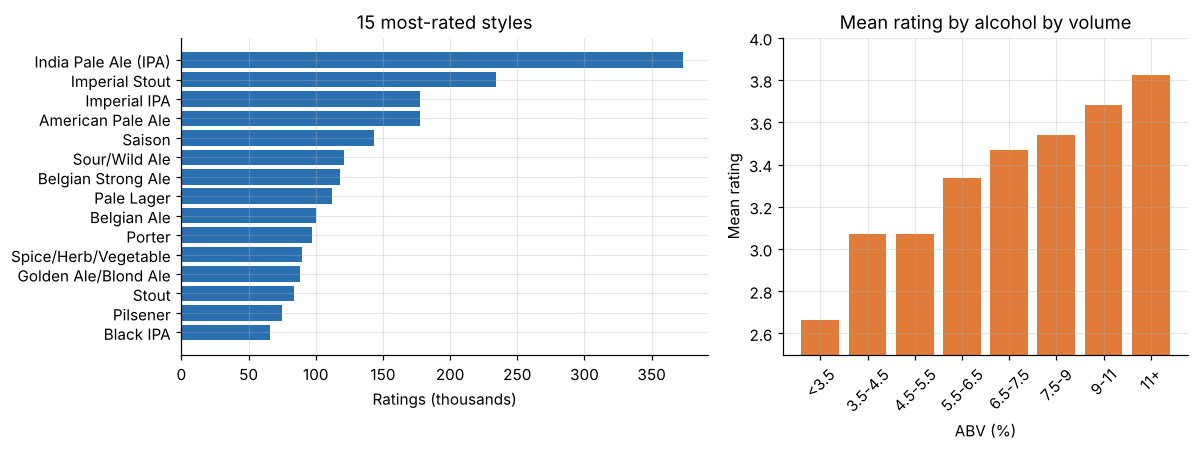

In [10]:
dfi = df.merge(items[["beer_id", "style", "abv", "abv_bin"]], on="beer_id")
top = dfi.groupby("style").rating.agg(["count", "mean"]).sort_values("count", ascending=False).head(15)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].barh(top.index[::-1], top["count"][::-1] / 1e3, color=BLUE)
ax[0].set(title="15 most-rated styles", xlabel="Ratings (thousands)")
order = ABV_LABELS
g = dfi[dfi.abv_bin != "unknown"].groupby("abv_bin").rating.agg(["mean", "count"]).reindex(order)
ax[1].bar(order, g["mean"], color=ORANGE)
ax[1].set(title="Mean rating by alcohol by volume", xlabel="ABV (%)", ylabel="Mean rating", ylim=(2.5, 4))
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{FIG}/fig3_styles_and_abv.png", bbox_inches="tight"); plt.show()

<details>
<summary><b>💡 What's going on here?</b></summary>

Two plots about the beer content:
- **Left – the 15 most-rated styles:** India Pale Ale (IPA) is by far the most rated style, followed by Imperial Stout and Imperial IPA.
- **Right – mean rating by alcohol content:** stronger beers get clearly higher ratings, from about 2.7 for beers under 3.5% to about 3.8 for beers over 11%. So ABV says something about how a beer will be rated.

</details>

In [11]:
# How much of the rating variation do the content features explain on their own?
# (share of variance explained by the per-group mean, i.e. eta squared)
tot = df.rating.var()
expl = {}
for f in ["style", "brewery_id", "country", "abv_bin"]:
    m = df.beer_id.map(items.set_index("beer_id")[f])
    expl[f] = 100 * df.rating.groupby(m).transform("mean").var() / tot
expl["beer (own id)"] = 100 * df.groupby("beer_id").rating.transform("mean").var() / tot
pd.Series(expl, name="% of rating variance explained").round(1).to_frame()

,% of rating variance explained
style,33.000000
brewery_id,39.700001
country,13.300000
abv_bin,16.000000
beer (own id),56.200001


<details>
<summary><b>💡 What's going on here?</b></summary>

This asks: *if we only knew one feature of a beer, how much of the variation in its ratings could we explain?* For each feature we replace every rating by the average rating of its group (e.g. its style) and see how much of the total variance that captures.

Style alone explains about a third of the variation. The numbers for brewery and especially the beer's own id are inflated, because groups with only a few ratings "explain" their own noise – the note under the table says the same.

</details>

Style alone explains about a third of the variation in ratings – a first sign that content features can stand in for missing ratings of new beers. *Caveat:* for features with very many values (brewery, and especially the beer's own id) this measure is inflated, because groups with only a few ratings fit their own noise.

## 1.4 How quickly do new beers collect ratings?
For beers whose first rating came in 2012–2016, how many ratings did they get within their first year?

295,160 beers first appeared 2012–2016.
Ratings in their first year: median 2, 75th percentile 6, 90th percentile 15
68% got fewer than 5 ratings and 84% fewer than 10 in their first year.


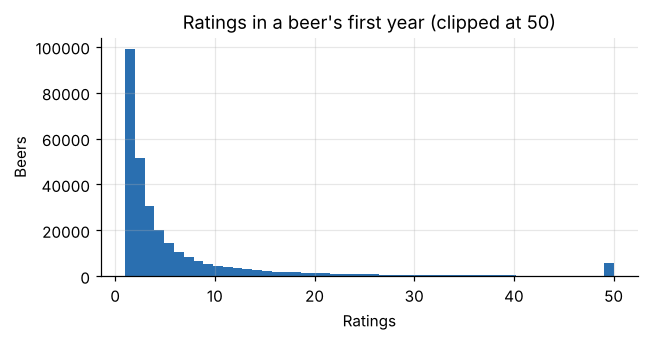

In [12]:
first = ratings.groupby("beer_id").date.min()
new = first[(first >= pd.Timestamp("2012-01-01").timestamp()) & (first < pd.Timestamp("2017-01-01").timestamp())]
r = ratings[ratings.beer_id.isin(new.index)]
within = r[r.date < r.beer_id.map(new) + 365 * 86400].groupby("beer_id").size()
q = within.describe(percentiles=[.25, .5, .75, .9])
print(f"{len(new):,} beers first appeared 2012–2016.")
print(f"Ratings in their first year: median {q['50%']:.0f}, 75th percentile {q['75%']:.0f}, 90th percentile {q['90%']:.0f}")
print(f"{100*(within < 5).mean():.0f}% got fewer than 5 ratings and {100*(within < 10).mean():.0f}% fewer than 10 in their first year.")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(within.clip(upper=50), bins=50, color=BLUE)
ax.set(title="Ratings in a beer's first year (clipped at 50)", xlabel="Ratings", ylabel="Beers")
plt.tight_layout(); plt.savefig(f"{FIG}/fig4_first_year_ratings.png", bbox_inches="tight"); plt.show()

<details>
<summary><b>💡 What's going on here?</b></summary>

For every beer that first appeared in 2012–2016, we count how many ratings it got in its **first year**.

The answer: the median new beer got only **2 ratings** in its first year, 68% got fewer than 5 and 84% fewer than 10. So most new beers stay almost unknown for a long time – this is the *cold-start problem* that recommender systems struggle with.

</details>

## 1.5 Save the prepared data for Task 2 and 3

In [13]:
df.to_parquet(f"{DATA}/filtered.parquet", index=False)
print(f"Saved {len(df):,} ratings, {df.user_id.nunique():,} users, {df.beer_id.nunique():,} beers")

Saved 3,765,057 ratings, 10,368 users, 129,965 beers


<details>
<summary><b>💡 What's going on here?</b></summary>

We save the filtered ratings as `filtered.parquet` in the `RateBeer Dataset` folder. **Parquet** is a compressed file format that loads much faster than CSV. The next notebook (`02_models_and_evaluation.ipynb`) reads this file, so this notebook must be run first.

</details>